# Per-fish and per-pair gains for my model: 10 cm / 5× vs 10 cm / 3× sure emitters

Joint fit $r_{i,p} \approx a_f\, b_p\, m_{i,f,p}$ on the sure-emitter EODs of all five 4-fish videos (Kaden masks, no offset),
from `EOD_fish_pair_factors_4fish_kaden_iso10_dom5.ipynb` and `..._iso10_dom3.ipynb`:
- sure emitter: midline ≥ 10 cm from every other fish's midline, predicted |v| at its top pair p* ≥ 5× (or 3×) every other
  fish's, largest recorded |v| at p* with the predicted sign, and only one fish passing;
- each EOD weighted by 1/‖r‖; pair gains normalised to a geometric mean of 1, so the fish gains carry V per model unit.

Bars: fit on all five videos, with 95% bootstrap intervals. Dots: the same fit on each video alone (missing when a video has
no sure EODs of that fish).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
%matplotlib inline

BASE, LET = 'results/eod_assign_4fish_kaden', 'ABCD'
OUT = f'{BASE}/fish_pair_factors_threshold_grid'; os.makedirs(OUT, exist_ok=True)
SETS = {'10 cm, 5×': f'{BASE}/fish_pair_factors_iso10cm_dom5', '10 cm, 3×': f'{BASE}/fish_pair_factors_iso10cm_dom3'}
COL = {'10 cm, 5×': '#1F5FBF', '10 cm, 3×': '#F08A24'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
F = {k: pd.read_csv(f'{v}/fish_pair_factors.csv', index_col=0) for k, v in SETS.items()}
VID = [c for c in F['10 cm, 5×'].columns if c.startswith('video ')]
T = pd.concat({k: f[['factor', '95% low', '95% high', 'n EODs'] + VID] for k, f in F.items()}, axis=1)
T.to_csv(f'{OUT}/gains_10cm_5x_vs_3x.csv')
display(T.xs('factor', axis=1, level=1).assign(**{'ratio 3× / 5×': lambda d: d['10 cm, 3×'] / d['10 cm, 5×']}).round(3))

,"10 cm, 5×","10 cm, 3×",ratio 3× / 5×
fish A,0.325,0.248,0.761
fish B,0.220,0.173,0.787
fish C,0.392,0.345,0.880
fish D,0.372,0.340,0.912
pair 1,1.130,1.218,1.078
pair 2,0.924,0.955,1.034
pair 3,0.886,0.844,0.953
pair 4,0.893,1.011,1.131
pair 5,1.239,1.406,1.134
pair 6,0.833,0.718,0.861


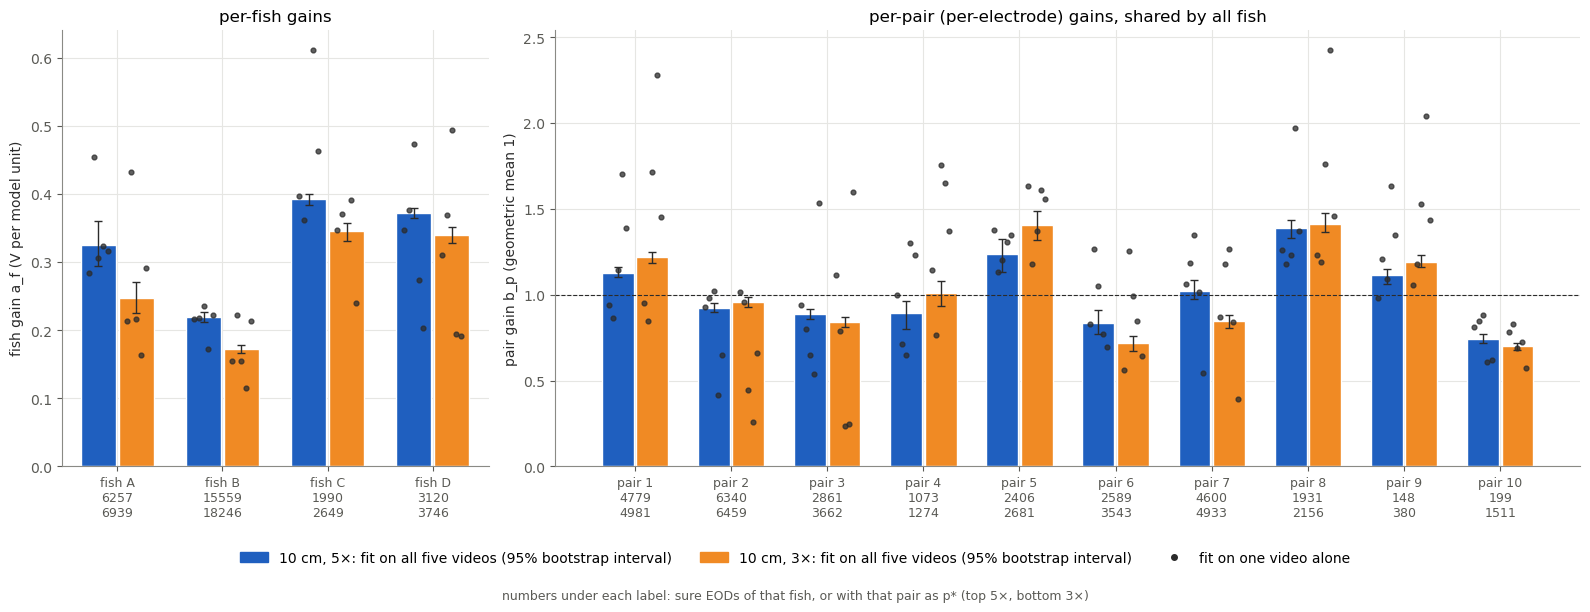

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw=dict(width_ratios=[1, 2.4]))
groups = [([f'fish {f}' for f in LET], 'fish gain a_f (V per model unit)', 'per-fish gains'),
          ([f'pair {p}' for p in range(1, 11)], 'pair gain b_p (geometric mean 1)', 'per-pair (per-electrode) gains, shared by all fish')]
w = 0.36
for ax, (names, ylab, title) in zip(axs, groups):
    x = np.arange(len(names))
    for k, (s, f) in enumerate(F.items()):
        xs = x + (k - 0.5) * w
        r = f.loc[names]
        ax.bar(xs, r['factor'], w * 0.92, color=COL[s], edgecolor='white', linewidth=1)
        ax.errorbar(xs, r['factor'], yerr=[r['factor'] - r['95% low'], r['95% high'] - r['factor']], fmt='none',
                    color='#2b2b2b', capsize=3, lw=1)
        for j, v in enumerate(VID):
            ax.scatter(xs + (j - 2) * 0.045, r[v], s=12, color='#2b2b2b', zorder=3, alpha=0.75)
    lab = [f'{n}\n{F["10 cm, 5×"].loc[n, "n EODs"]}\n{F["10 cm, 3×"].loc[n, "n EODs"]}' for n in names]
    ax.set(xticks=x, ylabel=ylab, title=title, ylim=(0, None))
    ax.set_xticklabels(lab, fontsize=9)
    if names[0].startswith('pair'): ax.axhline(1, color='#2b2b2b', lw=0.8, ls='--')
handles = [Patch(color=c, label=f'{s}: fit on all five videos (95% bootstrap interval)') for s, c in COL.items()]
handles.append(Line2D([], [], marker='o', ls='', color='#2b2b2b', ms=4, label='fit on one video alone'))
fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.text(0.5, -0.12, 'numbers under each label: sure EODs of that fish, or with that pair as p* (top 5×, bottom 3×)', ha='center', fontsize=9, color='#5a5a55')
plt.tight_layout(); fig.savefig(f'{OUT}/gains_10cm_5x_vs_3x.png', dpi=120, bbox_inches='tight'); plt.show()